# Stock forecaster: model report

This notebook explains and evaluates the model used by `app.py`. Training itself lives in
`train.py` (run `python train.py`, about 15 minutes on a CPU), so the app, the tests and this
report all use exactly the same code. Run this notebook after training to refresh the report.

**How the model works**

- Input: the last 100 trading days of six features built from returns, volume and the daily
  high-low range, all divided by the stock's own recent volatility (so any price level works).
- Output: for each of the next 100 trading days, the 10%, 50% and 90% quantiles of the price.
- Three LSTMs with different random seeds are averaged.
- Trained on 24 US and Indian stocks. Each stock is split by time: 70% train, 10% validation,
  20% test. Nothing in the test block was used for training or tuning.

In [1]:
import json
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import stock_utils as su      # import before anything that loads keras
import scenarios as sc
import train

logging.basicConfig(level=logging.WARNING)
art = su.load_artifacts()
meta = json.loads(su.META_PATH.read_text())
metrics = json.loads((su.MODEL_PATH.parent / 'metrics.json').read_text())
print('ensemble members :', meta['ensemble_members'])
print('trained on       :', ', '.join(meta['trained_on']))
print('data until       :', meta['data_until'])
print('median shrink    :', meta['median_shrink'], '(1 = use the model as is, 0 = "no change")')
print('range scale      :', meta['band_scale'])

I0000 00:00:1794666581.500129   18503 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794666581.539129   18503 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794666582.867839   18503 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


ensemble members : 3
trained on       : GOOG, AAPL, MSFT, AMZN, TSLA, NVDA, INTC, HDB, JPM, XOM, WMT, KO, BA, PFE, DIS, CAT, TCS.NS, BAJAJFINSV.NS, RELIANCE.NS, INFY.NS, HDFCBANK.NS, ITC.NS, SBIN.NS, LT.NS
data until       : 2026-11-13
median shrink    : 0.5 (1 = use the model as is, 0 = "no change")
range scale      : 0.98


## 1. Data

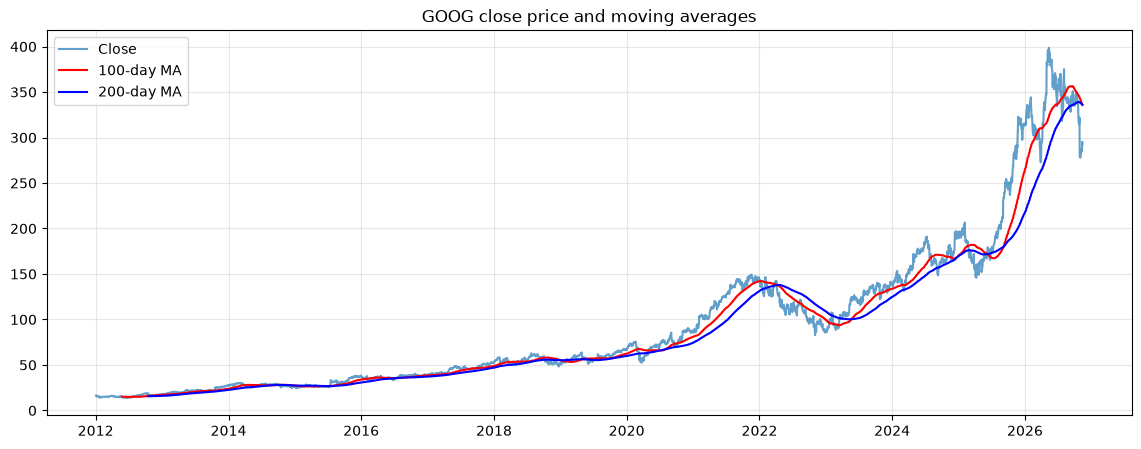

Price,Open,High,Low,Close,Volume
Date,,,,,
2026-11-09,290.545013,294.690002,285.940002,286.010010,24040000
2026-11-10,287.144989,289.500000,283.369995,284.920013,15135600
2026-11-11,287.565002,292.970001,286.899994,290.630005,18367500
2026-11-12,290.554993,299.250000,290.471985,295.350006,22186300
2026-11-13,299.894989,301.619995,290.339996,292.519989,18459000


In [2]:
stock = 'GOOG'
data = su.download_stock_data(stock, train.START)
pa = su.prepare(data)
close = data['Close']

plt.figure(figsize=(14, 5))
plt.plot(close, label='Close', alpha=0.7)
plt.plot(close.rolling(100).mean(), label='100-day MA', color='red')
plt.plot(close.rolling(200).mean(), label='200-day MA', color='blue')
plt.title(f'{stock} close price and moving averages'); plt.legend(); plt.grid(alpha=0.3); plt.show()
data.tail()

## 2. Test results (held-out last 20% of every stock)

Every 10 days in the test block, the model forecasts the next 100 days using only data up to that
day. Errors are MAPE in %. **Naive** ("the price does not change") is the benchmark to beat.

In [3]:
cols = [f'{h}d ahead' for h in metrics['horizons']]
o = metrics['overall']
overall = pd.DataFrame([o['model'], o['naive'], o['drift']], columns=cols,
                       index=['LSTM model', 'Naive (no change)', 'Drift (avg growth)'])
print(f"{o['forecasts']} forecasts across {len(metrics['per_ticker'])} stocks; "
      f"the 80% range contained the real price {o['coverage_80']}% of the time")
overall

1552 forecasts across 24 stocks; the 80% range contained the real price 75.6% of the time


,1d ahead,5d ahead,10d ahead,20d ahead,50d ahead,100d ahead
LSTM model,1.28,3.06,4.37,5.98,9.78,13.33
Naive (no change),1.29,3.08,4.38,6.00,9.82,13.38
Drift (avg growth),1.28,3.05,4.40,6.04,10.08,14.21


In [4]:
rows = {tk: {'model 20d': m['model'][3], 'naive 20d': m['naive'][3],
             'model 100d': m['model'][5], 'naive 100d': m['naive'][5],
             'inside 80% range (%)': m['coverage_80']} for tk, m in metrics['per_ticker'].items()}
per_ticker = pd.DataFrame(rows).T
better = int((per_ticker['model 100d'] < per_ticker['naive 100d']).sum())
print(f'Model beats naive at 100 days on {better} of {len(per_ticker)} stocks')
per_ticker

Model beats naive at 100 days on 12 of 24 stocks


,model 20d,naive 20d,model 100d,naive 100d,inside 80% range (%)
GOOG,6.76,7.03,15.71,16.57,69.6
AAPL,5.68,5.74,11.80,13.08,73.8
MSFT,5.15,5.04,12.37,12.13,75.8
AMZN,5.88,6.12,9.22,10.21,85.7
TSLA,11.60,11.21,23.35,22.37,78.9
NVDA,9.14,9.33,17.34,19.66,79.4
INTC,13.25,13.14,37.73,36.38,63.5
HDB,5.22,5.20,14.20,13.06,77.4
JPM,4.98,5.19,9.36,11.24,74.4
XOM,4.54,4.58,8.61,9.66,81.6


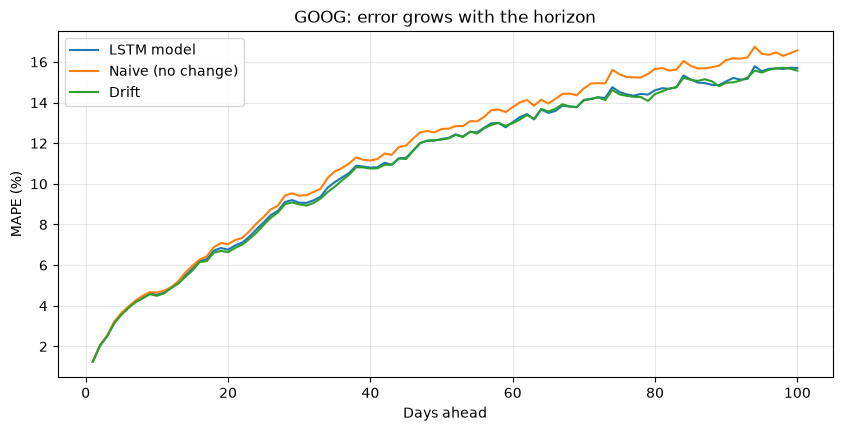

In [5]:
bt = su.walk_forward(art, pa, start_pos=train.split_positions(len(pa))[1])
plt.figure(figsize=(10, 4.5))
for key, label in [('model', 'LSTM model'), ('naive', 'Naive (no change)'), ('drift', 'Drift')]:
    plt.plot(range(1, su.HORIZON + 1), su.mape_by_horizon(bt['actual'], bt[key]), label=label)
plt.xlabel('Days ahead'); plt.ylabel('MAPE (%)'); plt.title(f'{stock}: error grows with the horizon')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 3. A forecast made 100 trading days ago vs. what happened

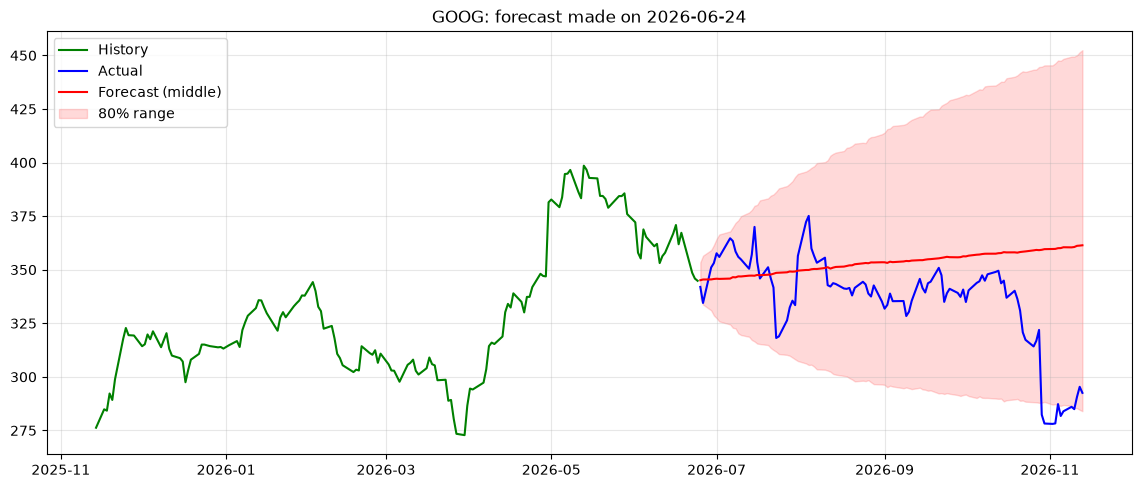

MAPE over the 100 days: 7.05%


In [6]:
def plot_forecast(fc, history, title, actual=None, paths=None):
    plt.figure(figsize=(14, 5.5))
    if paths is not None:
        plt.plot(fc.index, paths.T, color='gray', alpha=0.25, linewidth=0.8)
    plt.plot(history, color='green', label='History')
    if actual is not None:
        plt.plot(actual, color='blue', label='Actual')
    plt.plot(fc['Predicted'], color='red', label='Forecast (middle)')
    plt.fill_between(fc.index, fc['Lower'], fc['Upper'], color='red', alpha=0.15, label='80% range')
    plt.title(title); plt.legend(); plt.grid(alpha=0.3); plt.show()

t0 = len(pa) - 1 - su.HORIZON
past = su.forecast_path(art, pa, t=t0)
actual = close.iloc[t0 + 1:]
plot_forecast(past, close.iloc[t0 - 150:t0 + 1], f'{stock}: forecast made on {close.index[t0].date()}', actual)
print(f"MAPE over the 100 days: {np.mean(np.abs(past['Predicted'].values - actual.values) / actual.values) * 100:.2f}%")

## 4. Forecast from today, with example scenarios

The grey lines are simulated futures built from the stock's own past moves (including its crashes
and jumps) and stretched to agree with the model's range. The app's *Plan a trade* tab answers its
questions from 5,000 such paths.

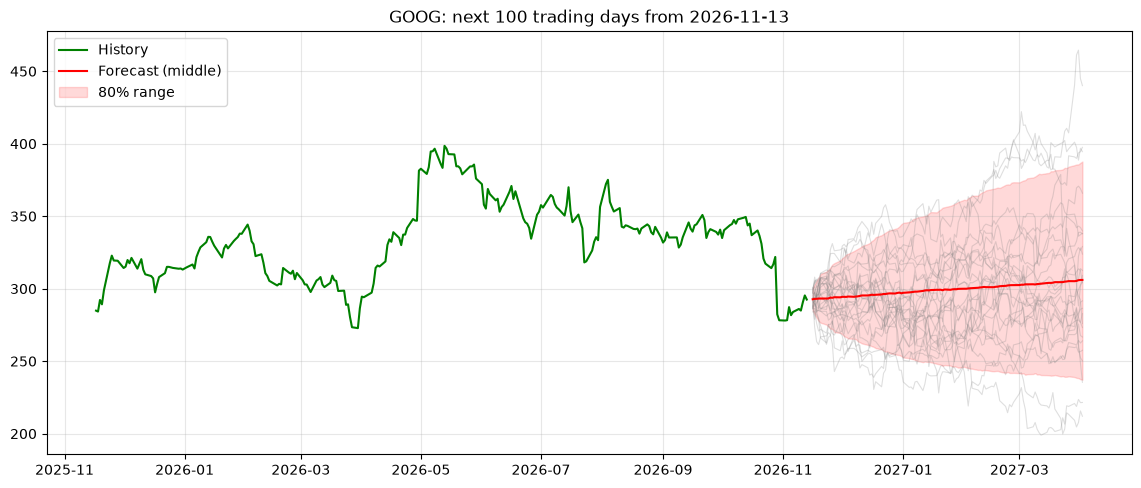

,Predicted,Lower,Upper
Date,,,
2026-11-16,292.72,285.12,300.30
2026-11-20,293.23,276.54,310.14
2026-11-27,294.11,270.07,317.63
2026-12-11,295.33,262.24,329.38
2027-01-22,299.46,247.33,356.22
2027-04-02,306.04,237.22,387.74


In [7]:
fc = su.forecast_path(art, pa)
paths = sc.simulate_paths(pa, fc[['Lower', 'Predicted', 'Upper']].to_numpy())
plot_forecast(fc, close.iloc[-250:], f'{stock}: next {su.HORIZON} trading days from {close.index[-1].date()}',
              paths=paths[:25])
fc.iloc[[0, 4, 9, 19, 49, 99]].round(2)

In [8]:
last = pa.close[-1]
target, stop, days, amount = last * 1.10, last * 0.95, 60, 50_000
print(f'Last close {last:.2f}; target {target:.2f}; stop-loss {stop:.2f}; {days} trading days')
print(f'Chance of closing above the target on day {days}: {sc.prob_above(paths, target, days):.0%}')
print('Target vs stop-loss:', {k: f'{v:.0%}' for k, v in sc.target_vs_stop(paths, target, stop, days).items()})
print('Outcome of investing', amount, ':', {k: round(v, 2) for k, v in sc.outcome_summary(paths, days, last, amount).items()})

Last close 292.52; target 321.77; stop-loss 277.89; 60 trading days
Chance of closing above the target on day 60: 33%
Target vs stop-loss: {'target_first': '40%', 'stop_first': '57%', 'neither': '3%'}
Outcome of investing 50000 : {'prob_loss': 0.43, 'bad_case_value': 39386.61, 'typical_value': 51343.92, 'good_case_value': 65517.41, 'bad_case_return': -0.21}


## 5. Were past probabilities right?

Each row is a chance the tool stated for the price finishing below some level; the columns show how
often that really happened (%) in the test block. Values close to the row label mean the
probabilities can be trusted for this stock.

In [9]:
table, n = sc.calibration_table(art, pa, start_pos=train.split_positions(len(pa))[1])
print(f'{stock}: based on {n} past forecasts')
table

GOOG: based on 65 past forecasts


,20 days,60 days,100 days
Stated chance,,,
5%,5.0,5.0,0.0
10%,8.0,8.0,2.0
25%,20.0,20.0,17.0
50%,34.0,32.0,34.0
75%,68.0,49.0,54.0
90%,85.0,74.0,77.0
95%,89.0,85.0,82.0
